# 04 — Evaluation and error analysis

Both models are evaluated **once** on the same 10 test instruments (3,435 notes), which neither model nor any choice
(epoch, hyperparameter, threshold) has seen:

- **Baseline**: MFCC mean/std + logistic regression, refitted exactly as in notebook 02 (deterministic).
- **CNN**: the best checkpoint of notebook 03 (chosen on the validation instruments), on the same 2.0 s crop.

Questions: does the CNN beat the baseline, which errors does it fix, is it learning *family* or *how the sound was
produced*, and how much should a single number on 10 instruments be trusted?

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "..")
from src.dataset import ROOT, load_metadata, load_notes, make_split, with_validation
from src.features import load_logmel, load_mfcc_stats
from src.train import FAMILIES, load_checkpoint, predict_logits

notes = with_validation(load_notes())  # split is "train" (fit), "val" or "test"
test = notes[notes["split"] == "test"].reset_index(drop=True)
y_test = test["family"].to_numpy()


def baseline():
    return make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))


# Baseline exactly as in notebook 02: trained on all 43 train instruments (fit + val).
train_all = notes[notes["split"] != "test"]
base = baseline().fit(load_mfcc_stats(train_all), train_all["family"])
pred_base = base.predict(load_mfcc_stats(test))

# CNN: best checkpoint, same crop as in training.
cnn, ckpt = load_checkpoint()
frames = ckpt["config"]["frames"]
X_test = np.ascontiguousarray(load_logmel(test)[:, :, :frames])
logits = predict_logits(cnn, X_test, ckpt["mean"], ckpt["std"])
pred_cnn = np.array(FAMILIES)[logits.argmax(1)]

out = test[["note", "instrument", "family", "source", "pitch", "velocity"]].assign(pred_baseline=pred_base, pred_cnn=pred_cnn)
out.to_csv(ROOT / "reports" / "test_predictions.csv", index=False)
print(f"CNN checkpoint: epoch {ckpt['epoch']}, validation balanced accuracy {ckpt['val_bacc']:.3f}, {frames} frames")
print(f"baseline test balanced accuracy {balanced_accuracy_score(y_test, pred_base):.3f} (notebook 02: 0.188)")

CNN checkpoint: epoch 6, validation balanced accuracy 0.584, 126 frames
baseline test balanced accuracy 0.188 (notebook 02: 0.188)


## 1. Headline comparison on the same test set

A third row answers a fairness question from notebook 03: the CNN was fitted on **36** instruments (7 went to
validation), the baseline on **43**. "Baseline (36 instruments)" is the same logistic regression fitted on exactly the
CNN's fit instruments.

In [2]:
fit_only = notes[notes["split"] == "train"]
pred_base36 = baseline().fit(load_mfcc_stats(fit_only), fit_only["family"]).predict(load_mfcc_stats(test))
preds = {"baseline (43 instr.)": pred_base, "baseline (36 instr.)": pred_base36, "CNN (36 instr.)": pred_cnn}
pd.DataFrame({
    name: {"balanced accuracy": balanced_accuracy_score(y_test, p), "accuracy": accuracy_score(y_test, p)}
    for name, p in preds.items()
}).T.round(3)

,balanced accuracy,accuracy
baseline (43 instr.),0.188,0.180
baseline (36 instr.),0.187,0.181
CNN (36 instr.),0.302,0.287


In [3]:
def per_family(pred):
    p, r, _, n = precision_recall_fscore_support(y_test, pred, labels=FAMILIES, zero_division=0)
    return pd.DataFrame({"recall": r, "precision": p}, index=FAMILIES), n

(rb, support), (rc, _) = per_family(pred_base), per_family(pred_cnn)
table = pd.concat({"baseline": rb, "CNN": rc}, axis=1)
table[("", "recall Δ")] = table[("CNN", "recall")] - table[("baseline", "recall")]
table[("", "test instrument")] = test.groupby("family")["instrument"].first()
table[("", "notes")] = support
table.round(2)

baseline              CNN                     \
           recall precision recall precision recall Δ   
bass         0.28      0.21   0.62      0.33     0.35   
brass        0.46      0.39   0.35      0.89    -0.10   
flute        0.00      0.00   0.02      1.00     0.02   
guitar       0.08      0.08   0.68      0.35     0.60   
keyboard     0.12      0.13   0.07      0.04    -0.05   
mallet       0.00      0.00   0.00      0.00     0.00   
organ        0.85      0.25   0.00      0.00    -0.85   
reed         0.09      0.32   0.90      0.29     0.80   
string       0.00      0.00   0.38      0.85     0.38   
vocal        0.01      0.10   0.00      0.00    -0.01   

                                         
                  test instrument notes  
bass           bass_synthetic_134   440  
brass          brass_acoustic_046   285  
flute         flute_synthetic_000   440  
guitar        guitar_acoustic_014   440  
keyboard  keyboard_electronic_002   440  
mallet        mallet_acoustic_047   220  
organ        organ_electronic_001   305  
reed            reed_acoustic_011   215  
string        string_acoustic_014   210  
vocal         vocal_synthetic_003   440

### Reading the headline numbers

- **The CNN reaches 0.302 balanced accuracy vs 0.188 for the baseline** (accuracy 0.287 vs 0.180), on the same split, the
  same test notes, both with balanced class weights. Chance is 0.10.
- **The fewer training instruments are not what matters here:** the baseline refitted on the CNN's 36 instruments scores
  0.187, the same as with 43. So the CNN's gain is not explained by data differences; if anything it had slightly less.
- **The gain is concentrated:** reed (+0.80), guitar (+0.60), string (+0.38) and bass (+0.35). Organ collapses
  (0.85 → 0.00), brass and keyboard drop slightly. Mallet, flute and vocal are ≈ 0 for both models.
- **Half the families are still at or near zero for the CNN** (flute 0.02, keyboard 0.07, mallet, organ and vocal 0.00). The
  0.30 comes from five families.
- **Precision tells the other half of the story.** The CNN puts 89% of its predictions into four families (guitar 25%,
  bass 25%, keyboard 21%, reed 19%), so their precision is low (0.04–0.35). Brass and string are the opposite: rarely
  predicted, but right when they are (precision 0.89 and 0.85).

## 2. Confusion matrices: which errors were fixed, which persist

Rows are the true family, normalised to sum to 1 (so the diagonal is recall).

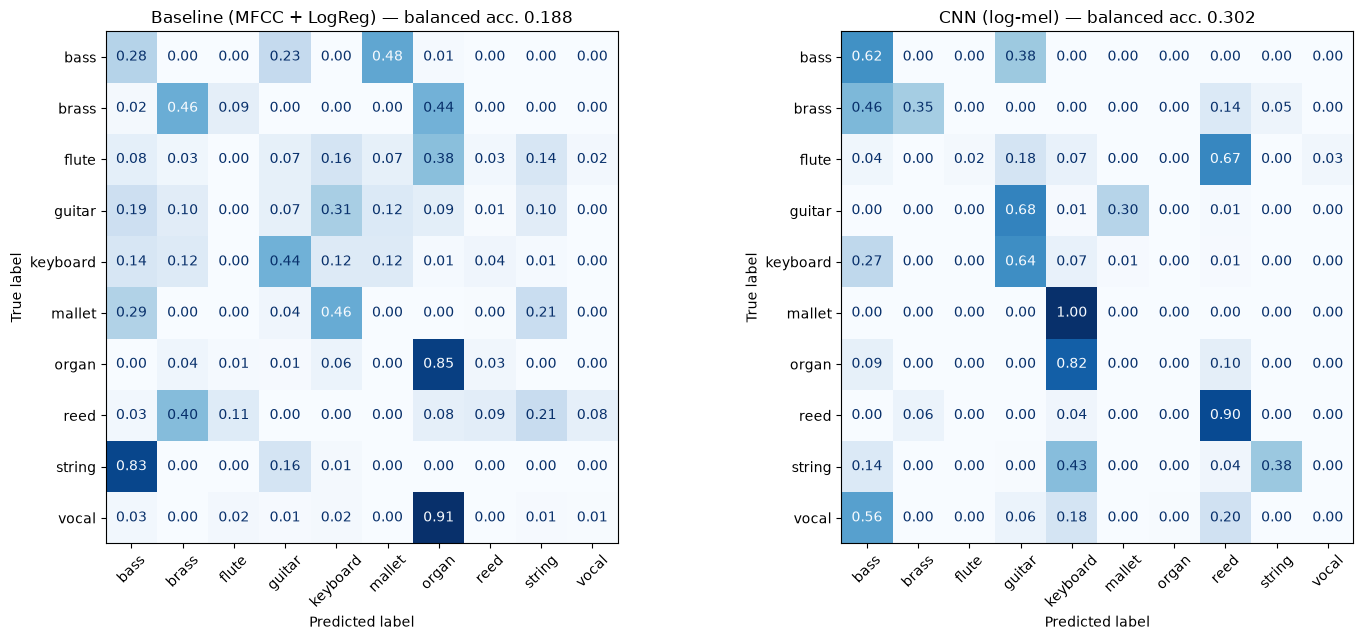

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (name, p) in zip(axes, [("Baseline (MFCC + LogReg)", pred_base), ("CNN (log-mel)", pred_cnn)]):
    ConfusionMatrixDisplay.from_predictions(y_test, p, labels=FAMILIES, normalize="true", values_format=".2f",
                                            cmap="Blues", xticks_rotation=45, colorbar=False, ax=ax)
    ax.set(title=f"{name} — balanced acc. {balanced_accuracy_score(y_test, p):.3f}")
plt.tight_layout()

In [5]:
cm = {name: pd.DataFrame(confusion_matrix(y_test, p, labels=FAMILIES, normalize="true"), index=FAMILIES, columns=FAMILIES)
      for name, p in [("baseline", pred_base), ("CNN", pred_cnn)]}
# The specific errors discussed in notebook 02, plus the CNN's own largest ones.
watch = [("mallet", "keyboard"), ("keyboard", "guitar"), ("reed", "brass"), ("vocal", "organ"), ("brass", "organ"),
         ("flute", "organ"), ("string", "bass"), ("bass", "mallet")]
off = cm["CNN"].where(~np.eye(10, dtype=bool)).stack().sort_values(ascending=False)
watch += [pair for pair in off.index[:5] if pair not in watch]
pd.DataFrame([{"true → predicted": f"{t} → {p}", "baseline": cm["baseline"].loc[t, p], "CNN": cm["CNN"].loc[t, p]}
              for t, p in watch]).set_index("true → predicted").round(2)

,baseline,CNN
true → predicted,,
mallet → keyboard,0.46,1.00
keyboard → guitar,0.44,0.64
reed → brass,0.40,0.06
vocal → organ,0.91,0.00
brass → organ,0.44,0.00
flute → organ,0.38,0.00
string → bass,0.83,0.14
bass → mallet,0.48,0.00
organ → keyboard,0.06,0.82


In [6]:
# Organ as the "default" class: how many NON-organ notes each model calls organ, and organ's precision.
non_organ = y_test != "organ"
pd.DataFrame({
    name: {"non-organ notes predicted organ": (p[non_organ] == "organ").mean(),
           "organ recall": (p[~non_organ] == "organ").mean(),
           "organ precision": (y_test[p == "organ"] == "organ").mean() if (p == "organ").any() else np.nan,
           "most predicted family": pd.Series(p).value_counts().index[0],
           "its share of all predictions": pd.Series(p).value_counts(normalize=True).iloc[0]}
    for name, p in [("baseline", pred_base), ("CNN", pred_cnn)]
}).T

,non-organ notes predicted organ,organ recall,organ precision,most predicted family,its share of all predictions
baseline,0.243131,0.852459,0.254652,organ,0.297234
CNN,0.000639,0.0,0.0,guitar,0.247162


In [7]:
# Note-level view: of the notes the baseline got wrong, how many does the CNN fix, and vice versa.
ok_b, ok_c = pred_base == y_test, pred_cnn == y_test
pd.crosstab(pd.Series(np.where(ok_b, "baseline right", "baseline wrong"), name=""),
            pd.Series(np.where(ok_c, "CNN right", "CNN wrong"), name=""), margins=True)

,CNN right,CNN wrong,All
,,,
baseline right,237,382,619
baseline wrong,749,2067,2816
All,986,2449,3435


### Is pitch a shortcut?

Notebook 01 noted that pitch ranges overlap across families, but not perfectly. Accuracy by pitch range, and the pitch of
the notes the CNN calls "bass":

In [8]:
bins = pd.cut(test["pitch"], [0, 48, 72, 128], labels=["low (<= 48)", "mid (49-72)", "high (> 72)"]).to_numpy()
display(pd.DataFrame({"baseline": pd.Series(ok_b).groupby(bins, observed=True).mean(),
                      "CNN": pd.Series(ok_c).groupby(bins, observed=True).mean(),
                      "notes": pd.Series(bins).value_counts()}).round(3))
wrong_bass = (pred_cnn == "bass") & (y_test != "bass")
print(f"median MIDI pitch of non-bass notes the CNN calls bass: {test['pitch'][wrong_bass].median():.0f} "
      f"(all test notes: {test['pitch'].median():.0f})")
test.assign(pred=pred_cnn).query("family in ['brass', 'keyboard']").groupby(["family", "pred"])["pitch"].agg(["size", "median"])

,baseline,CNN,notes
high (> 72),0.157,0.146,1405
low (<= 48),0.159,0.360,960
mid (49-72),0.230,0.407,1070


median MIDI pitch of non-bass notes the CNN calls bass: 80 (all test notes: 66)


size  median
family   pred                  
brass    bass       130    95.5
         brass      101    62.0
         reed        40    75.0
         string      14    77.0
keyboard bass       119    95.0
         guitar     281    62.0
         keyboard    32    41.0
         mallet       4    94.5
         reed         4    35.5

### Which errors were fixed, which persist

**Fixed:**
- **Organ as the "default" class is gone.** The baseline sent 24% of all non-organ notes to organ (91% of vocal, 44% of brass,
  38% of flute): after averaging over time, any steady tone looked like an organ. The CNN almost never predicts organ.
- **reed → brass** dropped from 0.40 to 0.06 (reed recall 0.09 → 0.90). Seeing the full spectrogram helps separate the two
  sustained wind families.
- **string → bass** (0.83 → 0.14) and **bass → mallet** (0.48 → 0.00).
- At note level the CNN fixes 749 notes the baseline got wrong and breaks 382 it got right.

**Persisting or worse:**
- **mallet → keyboard got worse: 0.46 → 1.00.** Every test mallet note is called keyboard. **keyboard → guitar also grew**
  (0.44 → 0.64). The struck/plucked, decaying group (mallet, keyboard, guitar) is still the hardest to separate, which is the
  opposite of what I expected from a model that sees the envelope. Possible contributors: the 2 s crop removes most of the
  difference in *decay length*, and mallet has only 2 training instruments. These are hypotheses; the next step is to listen
  to these notes.
- **The default class did not disappear, it moved.** Instead of "organ", the CNN's sinks are bass, guitar, keyboard and reed.
  New large errors: **organ → keyboard (0.82)**, **flute → reed (0.67)**, **vocal → bass (0.56)**, **brass → bass (0.46)**,
  **string → keyboard (0.43)**, **guitar → mallet (0.30)**.
- **Pitch matters for the CNN** (cell above). Below MIDI 72 the CNN is far better than the baseline (0.36–0.41 vs 0.16–0.23);
  above it, both are at ~0.15. "Bass" acts as a sink for *high* notes: the non-bass notes it calls bass have a median pitch of
  80 (all test notes: 66), and for brass and keyboard ~95. My guess is that at very high pitches
  only a few, widely spaced harmonics fit under the 8 kHz Nyquist limit, so there is little timbre left to see, and the model
  falls back on what it associated with sparse high spectra in training (NSynth's synthetic basses go up to MIDI 108).
  Not verified.

## 3. Confounding: family × source (acoustic / electronic / synthetic)

Notebook 01 showed that family and source are partly the same label in this data (organ is 100% electronic; brass,
mallet, reed, string 100% acoustic). A model could learn "this sounds synthetic" instead of "this is a flute".

**Caveat before reading accuracy per source:** on this test set, source and family are fully tied. Acoustic test notes
are brass, guitar, mallet, reed and string; electronic are keyboard and organ; synthetic are bass, flute and vocal.
So "accuracy on synthetic notes" is really "accuracy on these three test instruments".

In [9]:
pd.DataFrame({
    name: test.assign(ok=(p == y_test)).groupby("source")["ok"].mean()
    for name, p in [("baseline", pred_base), ("CNN", pred_cnn)]
}).assign(notes=test.groupby("source").size(),
          families=test.groupby("source")["family"].agg(lambda s: ", ".join(sorted(s.unique())))).round(3)

,baseline,CNN,notes,families
source,,,,
acoustic,0.134,0.491,1370,"brass, guitar, mallet, reed, string"
electronic,0.419,0.043,745,"keyboard, organ"
synthetic,0.094,0.214,1320,"bass, flute, vocal"


A more direct test. For each family, which sources exist among the **training** instruments the CNN was fitted on?
A prediction is **source-compatible** when the predicted family has at least one training instrument of the note's
source: a synthetic note called "bass" is compatible (there are synthetic basses in training); a synthetic note called
"brass" is not (all training brass is acoustic).

If a model mostly followed source, its predictions would be compatible far more often than chance. The reference is a
source-blind model that predicts families with the same overall frequencies but ignores the note's source.

In [10]:
fit_sources = fit_only.groupby("family")["source"].agg(set)
print("sources among the fit instruments:", {f: sorted(s) for f, s in fit_sources.items()})


def compatible(pred, source):
    return np.array([s in fit_sources[p] for p, s in zip(pred, source)])


rows = {}
for name, p in [("baseline", pred_base), ("CNN", pred_cnn)]:
    freq = pd.Series(p).value_counts(normalize=True)
    blind = np.mean([sum(freq.get(f, 0) for f in FAMILIES if s in fit_sources[f]) for s in test["source"]])
    obs = compatible(p, test["source"])
    rows[name] = {"source-compatible (observed)": obs.mean(), "source-blind reference": blind,
                  "wrong predictions that are compatible": obs[p != y_test].mean()}
pd.DataFrame(rows).T.round(3)

sources among the fit instruments: {'bass': ['electronic', 'synthetic'], 'brass': ['acoustic'], 'flute': ['acoustic'], 'guitar': ['acoustic', 'electronic'], 'keyboard': ['acoustic', 'electronic', 'synthetic'], 'mallet': ['acoustic'], 'organ': ['electronic'], 'reed': ['acoustic'], 'string': ['acoustic'], 'vocal': ['acoustic']}


,source-compatible (observed),source-blind reference,wrong predictions that are compatible
baseline,0.494,0.472,0.384
CNN,0.747,0.627,0.648


In [11]:
# Where do the synthetic flute and vocal notes go? Both families are acoustic-only in training.
pd.concat({name: pd.crosstab(test["family"], pd.Series(p, name="predicted"), normalize="index")
                 .loc[["flute", "vocal", "bass"]] for name, p in [("baseline", pred_base), ("CNN", pred_cnn)]}).round(2)

predicted        bass  brass  flute  guitar  keyboard  mallet  organ  reed  \
         family                                                              
baseline flute   0.08   0.03   0.00    0.08      0.16    0.08   0.38  0.03   
         vocal   0.03   0.00   0.02    0.01      0.02    0.00   0.91  0.00   
         bass    0.28   0.00   0.00    0.23      0.00    0.48   0.01  0.00   
CNN      flute   0.04   0.00   0.02    0.18      0.07    0.00   0.00  0.67   
         vocal   0.56   0.00   0.00    0.06      0.18    0.00   0.00  0.20   
         bass    0.62   0.00   0.00    0.38      0.00    0.00   0.00  0.00   

predicted        string  vocal  
         family                 
baseline flute     0.14   0.02  
         vocal     0.01   0.01  
         bass      0.00   0.00  
CNN      flute     0.00   0.03  
         vocal     0.00   0.00  
         bass      0.00   0.00

### Is the CNN learning "how it was produced" instead of "family"?

**Partly, yes, and more than the baseline.**

- Per source, the CNN is much better on acoustic notes (0.49 vs 0.13), better on synthetic (0.21 vs 0.09) and much worse on
  electronic (0.04 vs 0.42). But electronic here means just two instruments (keyboard and organ), and the baseline's 0.42
  was mostly its organ default. Per-source accuracy on this test set is per-instrument accuracy in disguise.
- The direct test: **75% of the CNN's predictions are source-compatible, vs 63% expected from a source-blind model with the
  same output frequencies** (+12 points). For the baseline the gap is +2 points (49% vs 47%). Among *wrong* predictions,
  65% of the CNN's are source-compatible vs 38% of the baseline's. When the CNN is wrong, it tends to pick a family that was
  produced the same way.
- The clearest cases: **synthetic vocal → bass (56%)**, bass being the main family with synthetic training instruments, and
  **electronic organ → keyboard (82%)**, both electronic. A counter-example: **synthetic flute → reed (67%)**, an acoustic-only
  family. There it follows the "sustained wind" timbre, not the source.

So the CNN uses production source as one of its cues. This data cannot fully separate the two, because source and family are
tied in the test set (each family is one instrument of one source). A clean test needs families recorded in several sources,
for example by adding instruments from NSynth's large `train` split.

## 4. How much does the split itself move the score?

The test set has 3,435 notes but only **10 instruments**, one per family. Per-family recall is measured on a single
instrument, and swapping one instrument can move balanced accuracy a lot. A bootstrap over notes would *underestimate*
this, because notes of the same instrument are strongly correlated: the effective sample size is closer to 10 than to 3,435.

The honest way to measure it is to redo the whole split. The baseline is cheap (features are cached, the fit takes
seconds), so it is refitted for **10 seeds of `make_split`** (seed 0 is the split used everywhere in this project).
The CNN is not retrained per seed (~25 min each); its single number has to be read with this spread in mind.

In [12]:
meta = load_metadata()
X_all = load_mfcc_stats(meta)
rows, recalls = [], []
for seed in range(10):
    split = make_split(meta, seed=seed)
    is_test = meta["instrument"].isin(split.loc[split["split"] == "test", "instrument"]).to_numpy()
    model = baseline().fit(X_all[~is_test], meta["family"][~is_test])
    p = model.predict(X_all[is_test])
    yt = meta["family"][is_test].to_numpy()
    rows.append({"seed": seed, "balanced accuracy": balanced_accuracy_score(yt, p),
                 "synthetic test instruments": int((split.loc[split["split"] == "test", "source"] == "synthetic").sum())})
    recalls.append(pd.Series(precision_recall_fscore_support(yt, p, labels=FAMILIES, zero_division=0)[1], index=FAMILIES, name=seed))
seeds = pd.DataFrame(rows).set_index("seed")
recalls = pd.concat(recalls, axis=1).T
print(f"baseline balanced accuracy over 10 splits: {seeds['balanced accuracy'].mean():.3f} ± {seeds['balanced accuracy'].std():.3f} "
      f"(min {seeds['balanced accuracy'].min():.3f}, max {seeds['balanced accuracy'].max():.3f})")
seeds.round(3).T

baseline balanced accuracy over 10 splits: 0.243 ± 0.062 (min 0.158, max 0.329)


seed,0,1,2,3,4,5,6,7,8,9
balanced accuracy,0.188,0.19,0.158,0.277,0.25,0.329,0.229,0.322,0.188,0.302
synthetic test instruments,3.000,2.00,2.000,1.000,4.00,1.000,4.000,2.000,2.000,3.000


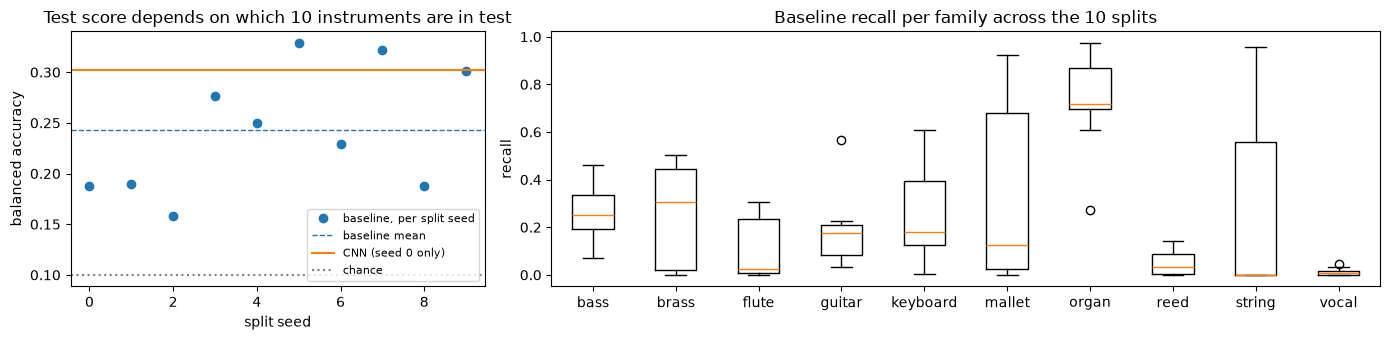

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [1, 2]})
axes[0].plot(seeds.index, seeds["balanced accuracy"], "o", label="baseline, per split seed")
axes[0].axhline(seeds["balanced accuracy"].mean(), color="C0", ls="--", lw=1, label="baseline mean")
axes[0].axhline(balanced_accuracy_score(y_test, pred_cnn), color="C1", label="CNN (seed 0 only)")
axes[0].axhline(0.1, color="gray", ls=":", label="chance")
axes[0].set(xlabel="split seed", ylabel="balanced accuracy", title="Test score depends on which 10 instruments are in test")
axes[0].legend(fontsize=8)
axes[1].boxplot([recalls[f] for f in FAMILIES], tick_labels=FAMILIES)
axes[1].set(title="Baseline recall per family across the 10 splits", ylabel="recall")
plt.tight_layout()

### Reading the split variance

- **Baseline over 10 splits: 0.243 ± 0.062** (range 0.158–0.329). The project's split (seed 0, 0.188) is one of the harder
  ones: 7 of the 10 seeds give a higher score.
- **Per family it is far worse:** across seeds, the baseline's string recall goes from 0.00 to 0.96, mallet from 0.00 to 0.92,
  keyboard from 0.00 to 0.61. Which instrument lands in test decides most of a family's score.
- **How to read the CNN's 0.302.** On the *same* split the CNN beats the baseline by +0.11, about 1.8× the baseline's
  seed-to-seed standard deviation. A paired comparison on one split is more informative than comparing to the spread, so
  this is suggestive evidence that the CNN is better. But it is one split and one training run: the CNN's own spread across
  splits is unknown (it could be larger, since it memorises more), and the baseline alone reaches 0.33 on another split.
  To claim a gain, I would train the CNN on 3–5 split seeds (~25 min each) and compare the paired differences.

## 5. My prediction vs the result

Recorded in notebook 03 before the final training run: *"Range 0.18–0.30, best guess ~0.23 … I wouldn’t be surprised if it
lands at or below the baseline."*

**Where my prediction went wrong.** The result (0.302) landed at the very top of my range and well above my best guess (0.23).
I was wrong about the cost of fewer training instruments: the baseline on the same 36 instruments scores 0.187, so losing 7
instruments was not the bottleneck I feared. I was also wrong about *where* the gain would come from: I expected the envelope
to fix mallet ↔ keyboard, which instead got worse (mallet → keyboard 0.46 → 1.00). The gain came from reed, guitar, string and bass,
and from the CNN no longer calling every steady tone an organ. I was right that reed ↔ brass would improve and that flute and
vocal would stay near zero.

## Takeaways

- **The CNN beats the baseline on the same split: 0.302 vs 0.188 balanced accuracy.** The baseline's seed spread (± 0.06) and
  the single CNN run mean this is suggestive, not proven.
- **It fixes some structured errors** (organ as default, reed → brass, string → bass) **and creates others** (mallet → keyboard
  1.00, organ → keyboard, high notes → bass). Half of the families are still near zero.
- **Its mistakes follow production source more than the baseline's do,** and it depends on pitch more than a timbre model
  should. Both are shortcuts available in this data.
- **The bottleneck is still data diversity:** one test instrument per family, 1–8 training instruments per family, and
  family partly confounded with source. More model capacity will not fix that; more instruments would.

### Limitations

- One test instrument per family: every per-family number is a per-instrument number.
- One CNN training run on one split; its variance across splits is unmeasured.
- Validation (7 families, no flute/vocal/mallet) chose the epoch; it is noisy and optimistic.
- The 2 s crop removes the late decay and the release.
- The CNN was not retrained on fit + validation instruments after choosing the epoch.